In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/0
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第0章 OSって個人で作れるの？ — 0.5 OS自作の全体像 (*Big Picture of MikanOS*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/0/0.5_Big_Picture_of_MikanOS.ipynb)

---

## 1. 導入：航海に出る前の「全体地図」

前節（0.4節）では、スモールステップ開発思想とベアメタルデバッグ戦略を学び、printf のない低レイヤ開発を生き抜くための武器を手に入れました。

しかし、OS自作という冒険において、開発者が直面するもう一つの巨大な壁があります。それは、**「いま自分が全体のどこを作っているのか分からなくなる遭難（迷子）現象」** です。

OSの開発では、特定のレジスタのビットマスク演算、ポインタのオフセット計算、アセンブリ命令のデバッグなど、極めてミクロで泥臭い作業が延々と続きます。
その作業に没頭するあまり、「なぜ今この構造体を定義しているのか」「この機能は最終的にどのサブシステムと繋がるのか」というマクロな視点を見失ってしまうと、学習のモチベーションが急速に減衰してしまいます。

### 本節で手に入れる3つの羅針盤
本書で作る **MikanOS** は、全30章（＋付録）にわたり、一行一行着実に機能を積み上げていく洗練されたアーキテクチャを持っています。
第1章の実装へ突入する前に、本節では以下の **「3大羅針盤」** を完全にインストールします：

1. **全30章・7大フェーズのアーキテクチャロードマップ**: 最小ブートローダから GUI マルチタスク OS への進化プロセスの全貌
2. **技術スタック選定の技術的必然性**: なぜレガシーBIOSではなく **UEFI** なのか、なぜ32bit x86ではなく **x86-64** なのか、なぜC言語ではなく **C++17/20** なのか
3. **システム階層アーキテクチャ（4層構造）**: ハードウェア・HAL・カーネルコア・サブシステム・ユーザーアプリの境界線と特権レベル（Ring 0 / Ring 3）の全容

## 2. MikanOS 全30章のアーキテクチャロードマップ（7大フェーズ）

MikanOS は、思いつきで機能を追加していくのではなく、OSの基盤となる低レイヤからユーザー空間の高度な抽象化へと、**7つのフェーズ** を経て段階的・有機的に成長します。

| Phase | フェーズ名 | 対象章 | 主要トピック & 実装マイルストーン | 中核データ構造 / ハードウェア |
|:---:|---|:---:|---|---|
| **Phase 1** | **ブートとグラフィックス基盤** | 第1章 〜 第5章 | UEFI EDK II ブートローダ、GOP フレームバッファ取得、PixelWriter 多態性、Hankaku フォント展開、Console と printk | `PixelWriter`, `PixelFormat`, `Console`, `FrameBufferConfig` |
| **Phase 2** | **入力デバイスと割り込み機構** | 第6章 〜 第7章 | PCI コンフィギュレーション空間探索、xHCI (USB 3.0) コントローラ初期化、IDT (割り込み記述子表)、MSI 割り込み、ArrayQueue (リングバッファ) | `IDTEntry`, `InterruptDescriptorTable`, `ArrayQueue`, `PCIConfig` |
| **Phase 3** | **メモリ管理とGUIレイヤ重ね合わせ** | 第8章 〜 第10章 | GDT (セグメンテーション) 初期化、BitmapMemoryManager (4KiB物理フレーム管理)、new/delete ヒープ、LayerManager (Z-order 重ね合わせ合成)、ShadowBuffer (ダブルバッファ) | `BitmapMemoryManager`, `SegmentDescriptor`, `Layer`, `LayerManager`, `Window` |
| **Phase 4** | **時間計測・キーボードとマルチタスク** | 第11章 〜 第14章 | Local APIC タイマ割り込み、ACPI PM タイマ較正、TimerManager (優先度付きキュー)、USB HID キーボード、TaskContext と SwitchContext アセンブリ、マルチレベル優先度スケジューラ | `TaskContext`, `Task`, `TaskManager`, `Timer`, `TimerManager` |
| **Phase 5** | **ターミナル・コマンドとファイル** | 第15章 〜 第18章 | Terminal 独立スレッド化、キーイベントディスパッチ、echo/clear/lspci コマンド、FAT32 BPB・ディレクトリエントリ解析、ELF64 アプリケーションバイナリロード | `Terminal`, `FAT32Header`, `DirectoryEntry`, `Elf64_Ehdr`, `Elf64_Phdr` |
| **Phase 6** | **4階層ページングとシステムコール保護** | 第19章 〜 第23章 | 48ビット正規仮想アドレス・4階層ページテーブル (PML4/PDP/PD/PT)、Ring 0 / Ring 3 空間分離、TSS・IST、SYSCALL/SYSRET 命令、GUI アプリ API (描画・イベント) | `PML4Table`, `PDPTable`, `PageDirectory`, `TSS64`, `SyscallArgs` |
| **Phase 7** | **実用OSへの洗練・IPCとアプリケーション** | 第24章 〜 第30章 | 複数ターミナル起動、PML4 タスク独立化、ファイル書き込み (FAT クラスタ割り当て)、標準入力抽象化、デマンドページング & Copy-on-Write、FreeType 日本語フォント、パイプ IPC、実用アプリ群 | `FileDescriptor`, `PipeDescriptor`, `DemandPageManager`, `FreeTypeFont` |

### モジュール間の依存関係グラフ (DAG)
各モジュールは、必ず **「過去の章で完成させた下位モジュール」** を土台にして構築されます。循環依存は一切存在せず、完全な有向非巡回グラフ（DAG: *Directed Acyclic Graph*）を形成しています。

```mermaid
flowchart TD
    subgraph Phase1["Phase 1: ブート & 画面表示"]
        UEFI["UEFI Bootloader (EDK II)"] --> GOP["GOP FrameBuffer"]
        GOP --> PW["PixelWriter"]
        PW --> Cons["Console & printk"]
    end
    
    subgraph Phase2["Phase 2: デバイス & 割り込み"]
        PCI["PCI Bus Manager"] --> xHCI["xHCI (USB 3.0) Driver"]
        IDT["IDT & Interrupt Handlers"]
        Queue["ArrayQueue (FIFO)"]
        xHCI --> Queue
        IDT --> Queue
    end
    
    subgraph Phase3["Phase 3: メモリ & レイヤ"]
        BMM["BitmapMemoryManager (4KiB)"]
        PW --> LM["LayerManager (Z-order)"]
        BMM --> LM
    end
    
    subgraph Phase4["Phase 4: タイマ & マルチタスク"]
        IDT --> Timer["TimerManager (Local APIC)"]
        Timer --> Sched["TaskManager & Scheduler"]
    end
    
    subgraph Phase5["Phase 5: ファイル & コマンド"]
        Cons --> Term["Terminal Task"]
        LM --> Term
        Sched --> Term
        FAT["FAT32 FileSystem"]
        FAT --> ELF["ELF64 App Loader"]
    end
    
    subgraph Phase6["Phase 6: 仮想メモリ & システムコール"]
        BMM --> Page["4-Level Paging (PML4)"]
        Sched --> Syscall["SYSCALL/SYSRET (Ring 3 Separator)"]
        Page --> Syscall
        LM --> AppGUI["App Window GUI API"]
        Syscall --> AppGUI
    end
    
    subgraph Phase7["Phase 7: IPC & 実用アプリ"]
        Syscall --> Pipe["Pipe IPC Descriptor"]
        AppGUI --> Apps["User Apps (Paint, Blocks, Viewers)"]
    end
```

## 3. 技術スタック選定の技術的必然性（なぜUEFI・x86-64・C++なのか）

自作OSの世界には、数多くのアーキテクチャや言語の選択肢が存在します。
なぜ MikanOS は、往年の自作OS本で定番だった「レガシーBIOS ＋ 32ビットx86 ＋ C言語/アセンブリ」という組み合わせを捨て、**「UEFI BIOS ＋ x86-64 (AMD64) ＋ C++17/20」** を採用したのでしょうか？
この選択には、OSの教育的・工学的な **「決定的な必然性」** があります。

### 3.1 ファームウェア選定：UEFI BIOS vs レガシーBIOS (MBR)

1980年代の IBM PC/AT 互換機から続く **レガシーBIOS（*Legacy BIOS*）** は、現代のOS学習者にとって最大の「落とし穴」でした。

| 比較項目 | レガシーBIOS (MBR) | UEFI (EDK II) — MikanOS採用 |
|---|---|---|
| **起動時のCPUモード** | **16ビットリアルモード**（1MBの物理メモリしか見えない） | **64ビットロングモード**（全物理メモリへ最初からアクセス可能） |
| **ブートコードサイズ制限** | **わずか512バイト**（MBRセクタ1つ分） | **事実上無制限**（数MBのELF/PEバイナリも一発で配置可能） |
| **ファイルアクセス** | 不可（BIOS割り込み INT 13h でCHSセクタを手動読み込み） | **標準装備**（FAT12/16/32 ファイルシステムドライバがファームウェア内蔵） |
| **画面グラフィックス** | VGA 320x200 256色モード（VRAM 0xA0000） | **GOP (*Graphics Output Protocol*)** によるフルカラー・高解像度（1024x768等） |
| **メモリマップ取得** | 不安定な BIOS INT 15h AX=E820h の連続呼び出し | `GetMemoryMap()` による統一されたディスクリプタ配列取得 |

> [!NOTE]
> **歴史的負債のパズル vs OSの本質**:
> レガシーBIOSからOSを作ると、16ビットリアルモードからA20ラインを開放し、GDTを設定して32ビットプロテクトモードへ移行し、さらにページングを有効化して64ビットロングモードへ移行するという「本質的でない歴史的パズル」に本全体の半分以上のページを費やすことになります。
> UEFIを採用することで、これらの歴史的パズルを完全にスキップし、**第1章・第2章からいきなり64ビット現代OSの本質的なコアロジック**（メモリマップ解析、ピクセル描画、割り込み）に直入できます。

---

### 3.2 CPUアーキテクチャ選定：x86-64 (AMD64) vs 32-bit x86 / ARM

自作OSのターゲットCPUとして、MikanOS は現代のデスクトップ・ノートPCの事実上の標準である **x86-64 (AMD64)** を採用しています。

1. **フラットな48ビット正規仮想アドレス空間**:
   32ビットx86のような 4GiB の狭いアドレス空間（セグメンテーションによる継ぎ接ぎ）ではなく、広大な $2^{48} = 256\text{ TiB}$ の空間を4階層ページング（PML4 / PDP / PD / PT）で美しく分割管理できます。
2. **高速システムコール命令（`SYSCALL` / `SYSRET`）**:
   従来のソフトウェア割り込み（`int 0x80`）による低速なRing 0遷移ではなく、AMD/Intelの現代的プロセッサが提供する専用MSR（*Model Specific Register*：`IA32_STAR`, `IA32_LSTAR`, `IA32_SFMASK`）を用いた最先端の超高速システムコール機構を直接実装・体験できます。
3. **実機ブートの確実性**:
   QEMUなどの仮想マシンだけでなく、手元にある Intel Core / AMD Ryzen 搭載の物理PCにUSBメモリを挿すだけで、そのままネイティブブートできる圧倒的な達成感を得られます。

---

### 3.3 開発言語選定：C++ (C++17/20) vs 純粋C言語 vs Rust

「OSはC言語かアセンブリで書くもの」という固定観念を覆し、MikanOS は **C++（C++17/C++20）** をメイン言語として採用しています。

| 特徴 | 純粋C言語 (C99/C11) | C++ (C++17/20) — MikanOS採用 | Rust |
|---|---|---|---|
| **ハードウェア直結制御** | ポインタ演算による直接MMIO操作（最高） | ポインタ直接操作・インラインアセンブリ完全対応 | `unsafe` ブロックが頻発する |
| **オブジェクト指向抽象化** | 手動の関数ポインタ構造体（vtableを自力構築） | **言語ネイティブの `class` と仮想関数** | トレイトによる抽象化 |
| **型安全なジェネリクス** | `void*` による型消去（キャストミス・バグの温床） | **C++テンプレート** によるゼロオーバーヘッド型安全 | ジェネリクスとトレイト境界 |
| **機械語の透過性** | 極めて高い（ソースと機械語がほぼ1対1対応） | **高い**（例外・RTTIを切ればCと同等の極小バイナリ） | コンパイラによる最適化が高度で追跡が難しい |
| **OS入門の教育的見通し** | ウィンドウ・レイヤ管理で手動vtableコードが破綻 | **ハードウェアの泥臭さとGUIの美しさが完璧に共存** | 所有権・借用チェッカーの学習コストが支配的 |

> [!IMPORTANT]
> **フリースタンディング環境における C++ の「ゼロコスト抽象化」**:
> MikanOS では、コンパイラフラグ `-ffreestanding -fno-exceptions -fno-rtti` を指定し、重厚な標準C++ライブラリ（`libstdc++`）や例外処理のランタイム機構を排除しています。
> これにより、**「ランタイムオーバーヘッドは純粋C言語と完全に同一（ゼロコスト）」でありながら、「クラス・カプセル化・ポリモーフィズム・テンプレート」という強力な言語機能の恩恵を100%享受** できます。

## 4. MikanOS 4層システム階層アーキテクチャ

MikanOS は、シリコン（物理ハードウェア）から最上位のデスクトップGUIアプリケーションまで、明確に定義された **4つの階層（Tiers）** で構成されています。

```text
+-----------------------------------------------------------------------------------+
|  4. Userland Applications (Ring 3: 非特権ユーザー空間)                             |
|     - Terminal (コマンドシェル), Calc (計算機), Paint (お絵描き), Blocks (ゲーム)   |
|     - Standard Library: Newlib libc (printf, malloc, exit, open, read, write)     |
+===================================================================================+
                               ▲  特権境界 (Privilege Boundary)
                               │  SYSCALL / SYSRET 命令 & 仮想アドレス空間分離 (CR3)
                               ▼
+-----------------------------------------------------------------------------------+
|  3. OS Subsystems & Window Compositor (Ring 0: カーネル空間)                      |
|     - LayerManager: Z-order 重ね合わせ合成 & 差分再描画最適化                     |
|     - ShadowBuffer: チラつきのないダブルバッファリング描画                        |
|     - FATFileSystem: FAT32 BPB/クラスタ追跡 & ディレクトリエントリ管理             |
|     - ELFLoader: ELF64 バイナリヘッダ解析 & プログラムセグメントロード             |
|     - PipeManager: プロセス間通信 (IPC) パイプバッファ                            |
+-----------------------------------------------------------------------------------+
|  2. Kernel Core Subsystems (Ring 0: カーネル空間)                                 |
|     - 4-Level Paging: PML4 / PDP / PD / PT による仮想メモリ保護                    |
|     - BitmapMemoryManager: 4KiB 物理ページフレームアロケータ                       |
|     - TaskManager & Scheduler: TaskContext 切り替え & マルチレベル優先度キュー     |
|     - IDTManager: 割り込み記述子表登録 & CPU 例外ハンドリング                      |
|     - TimerManager: Local APIC タイマ割り込み & ACPI PM タイマ較正                 |
+-----------------------------------------------------------------------------------+
|  1. Hardware & HAL / Device Drivers (ハードウェア抽象化層)                        |
|     - GOP FrameBuffer: UEFI ファームウェアから引き継いだリニアフレームバッファ     |
|     - xHCI Host Controller Driver: PCI 経由での USB 3.0 マウス・キーボード制御     |
|     - PCI Bus Enumerator: CONFIG_ADDRESS / CONFIG_DATA によるバス探索              |
|     - CPU Control: CR0/CR3/CR4, EFER, STAR/LSTAR/SFMASK MSRs, GDTR/IDTR           |
+-----------------------------------------------------------------------------------+
```

この階層構造を頭に入れておくことで、以降の各章で実装するクラスが **「どの階層に属し、どのハードウェア/上位層と対話しているのか」** が一目瞭然となります。

In [2]:
# C++20 による MikanOS アーキテクチャロードマップ & 技術スタック検証コードのコンパイルと実行
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
cpp_source = repo_root / "src" / "ch00" / "os_architecture_roadmap.cpp"
bin_output = repo_root / "build" / "bin" / "ch00_os_architecture_roadmap"
bin_output.parent.mkdir(parents=True, exist_ok=True)

print(f"C++20 検証コードをコンパイル中: {cpp_source.name} ...")
cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic",
    str(cpp_source), "-o", str(bin_output)
]
compile_res = subprocess.run(cmd, capture_output=True, text=True)
if compile_res.returncode != 0:
    print("❌ コンパイルエラー:")
    print(compile_res.stderr)
else:
    print("✅ コンパイル成功！実行中...\n")
    exec_res = subprocess.run([str(bin_output)], capture_output=True, text=True)
    print(exec_res.stdout)


C++20 検証コードをコンパイル中: os_architecture_roadmap.cpp ...


✅ コンパイル成功！実行中...

 MikanOS Architecture Roadmap & Tech Stack Verification (C++20)  

--- 1. Seven Evolutionary Phases of MikanOS ---
[Phase 1] ブートとグラフィックス基盤 (第1章 〜 第5章) : 5 milestones
[Phase 2] 入力デバイスと割り込み機構 (第6章 〜 第7章) : 5 milestones
[Phase 3] メモリ管理とGUIレイヤ重ね合わせ (第8章 〜 第10章) : 5 milestones
[Phase 4] 時間計測・キーボードとマルチタスク (第11章 〜 第14章) : 5 milestones
[Phase 5] ターミナル・コマンドとファイルシステム (第15章 〜 第18章) : 5 milestones
[Phase 6] 4階層ページングとシステムコール保護 (第19章 〜 第23章) : 6 milestones
[Phase 7] 実用OSへの洗練・IPCとアプリケーション (第24章 〜 第30章) : 6 milestones

--- 2. Module Dependency Graph Validation ---
Dependency graph DAG status: VALID (No Cycles / Chronological)

Module Name         Chapter   Layer             Depth   Dependencies
----------------------------------------------------------------------
PixelWriter         Ch.4     Hardware / HAL    0       (none)
Console             Ch.5     Kernel Core       1       PixelWriter
PCIManager          Ch.6     Hardware / HAL    0       (none)
xHCIDriver          Ch.6     Har

## 5. ハードウェア・アーキテクチャ視覚化図版の生成

### 5.1 図版 1: MikanOS 全体レイヤアーキテクチャと7大フェーズロードマップ
以下のセルを実行し、MikanOS の 4層システム階層（上段）と、全30章にわたる 7大フェーズの進行タイムライン（下段）を高解像度図版（DPI 300）として生成・保存します。

図版 1 を保存しました: fig0_9_mikanos_overall_architecture_map.png (907,059 bytes)


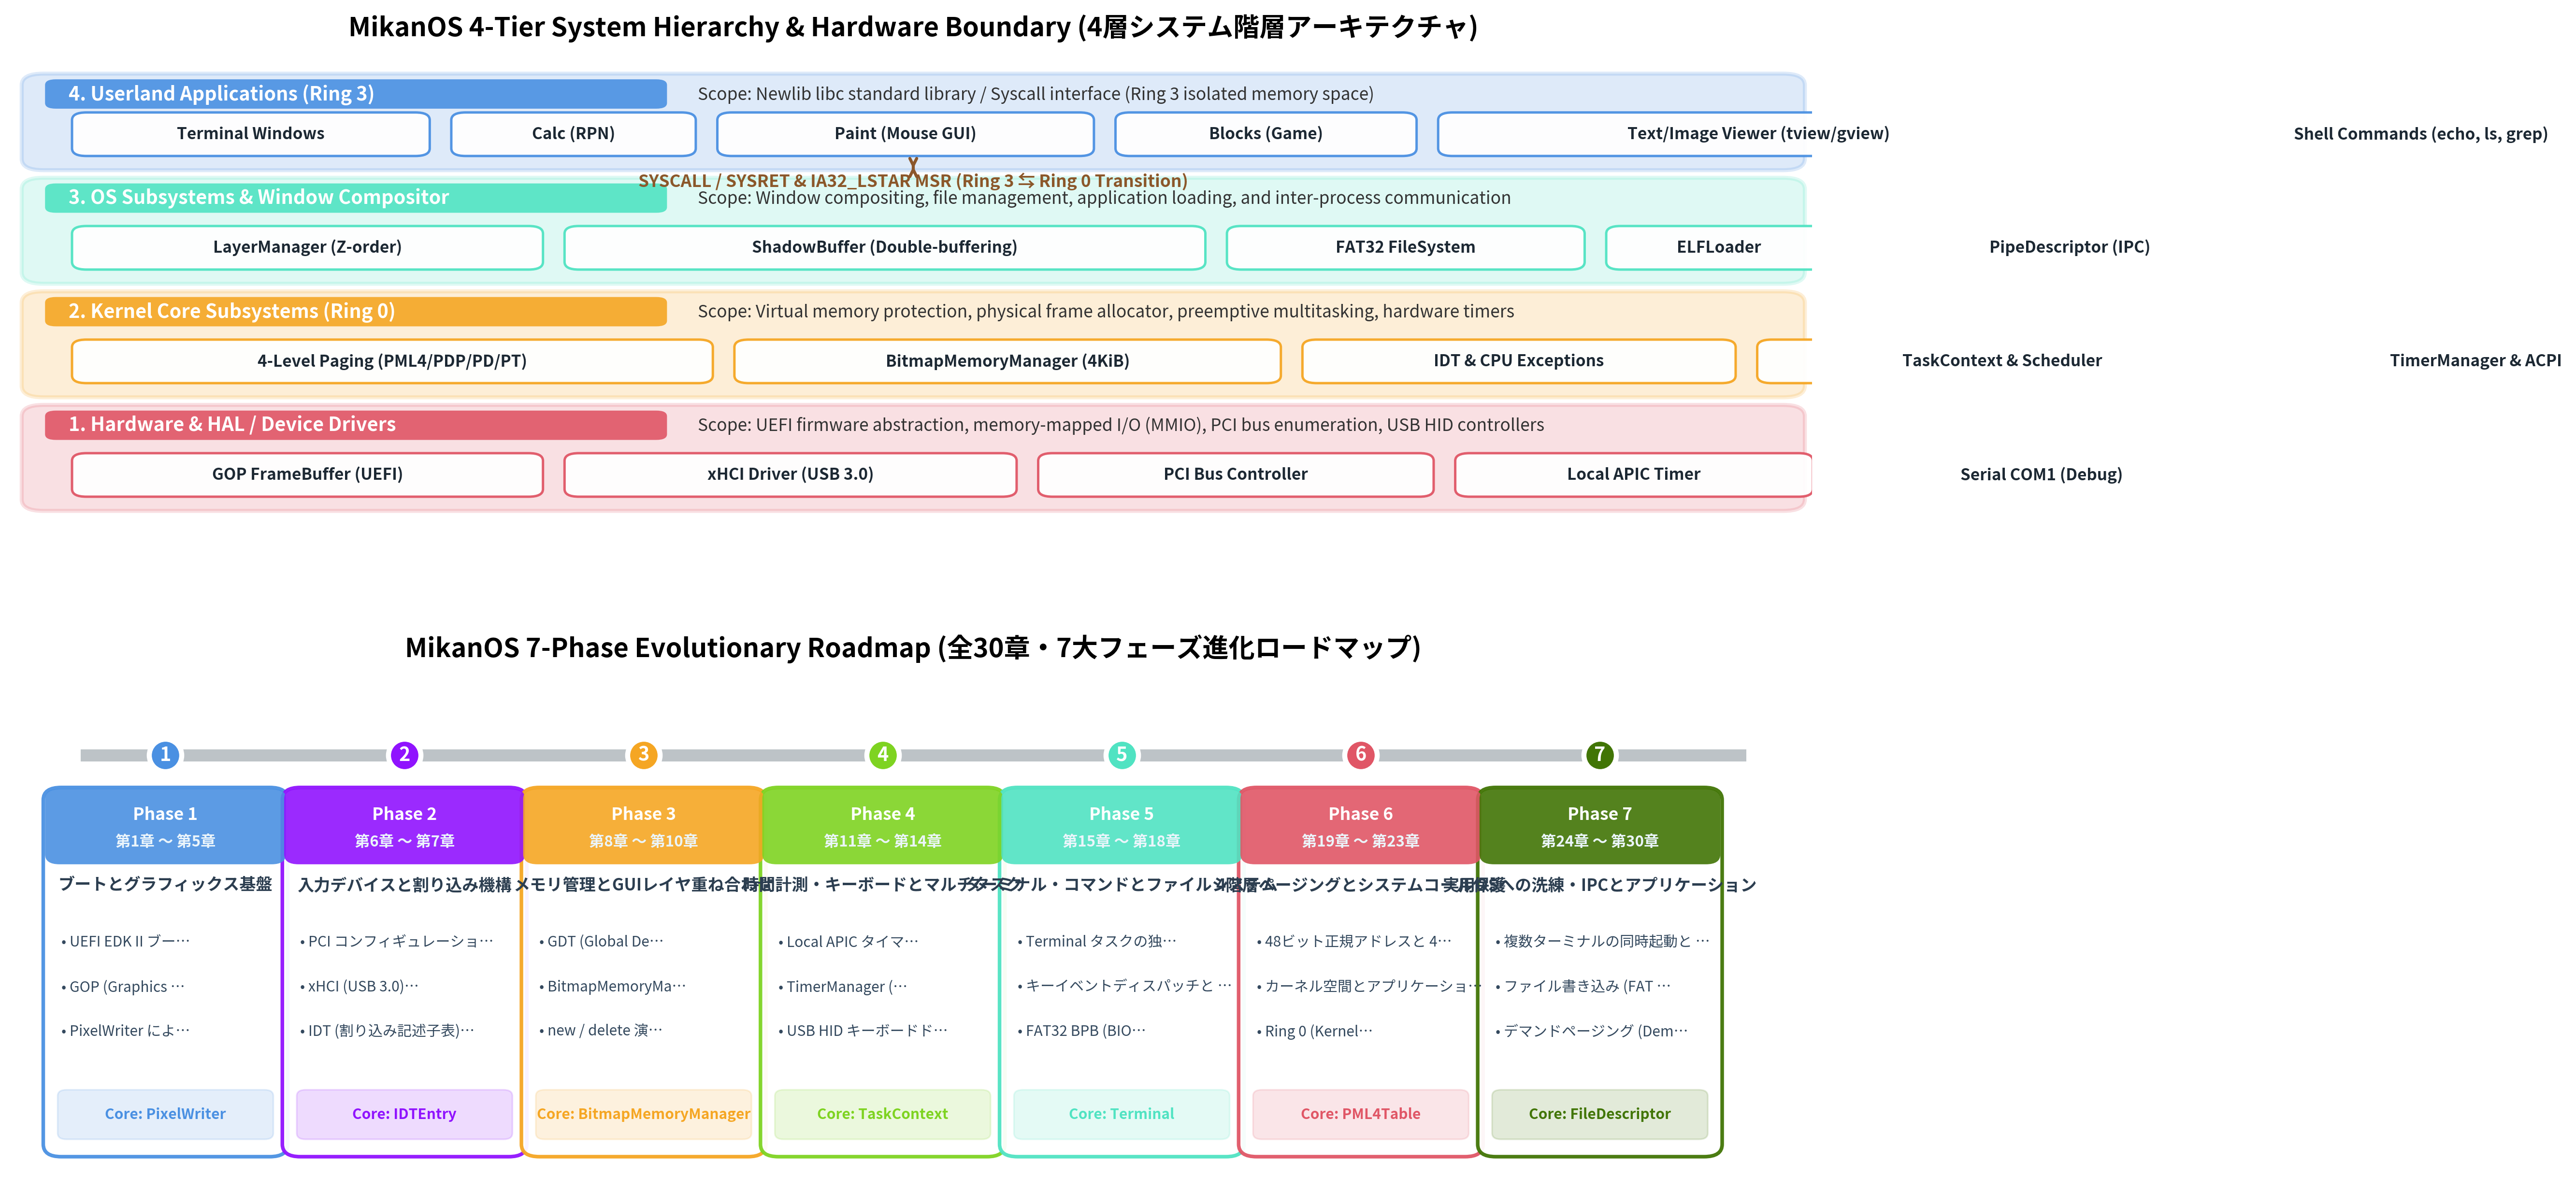

In [3]:
# 図版生成 1: MikanOS 全体レイヤアーキテクチャと7大フェーズロードマップ
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style, MikanOSArchitectureRoadmap

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(16, 10), dpi=300)
gs = fig.add_gridspec(2, 1, height_ratios=[1.1, 1.2], hspace=0.35)

# --- Top Subplot: 4-Tier System Architecture ---
ax_arch = fig.add_subplot(gs[0])
ax_arch.set_title("MikanOS 4-Tier System Hierarchy & Hardware Boundary (4層システム階層アーキテクチャ)", fontsize=13, weight="bold", pad=12)
ax_arch.set_xlim(0, 100)
ax_arch.set_ylim(0, 48)
ax_arch.axis("off")

layers = [
    (37, 9, "4. Userland Applications (Ring 3)", "#4A90E2", 
     ["Terminal Windows", "Calc (RPN)", "Paint (Mouse GUI)", "Blocks (Game)", "Text/Image Viewer (tview/gview)", "Shell Commands (echo, ls, grep)"],
     "Newlib libc standard library / Syscall interface (Ring 3 isolated memory space)"),
    (25, 10, "3. OS Subsystems & Window Compositor", "#50E3C2",
     ["LayerManager (Z-order)", "ShadowBuffer (Double-buffering)", "FAT32 FileSystem", "ELFLoader", "PipeDescriptor (IPC)"],
     "Window compositing, file management, application loading, and inter-process communication"),
    (13, 10, "2. Kernel Core Subsystems (Ring 0)", "#F5A623",
     ["4-Level Paging (PML4/PDP/PD/PT)", "BitmapMemoryManager (4KiB)", "IDT & CPU Exceptions", "TaskContext & Scheduler", "TimerManager & ACPI"],
     "Virtual memory protection, physical frame allocator, preemptive multitasking, hardware timers"),
    (1, 10, "1. Hardware & HAL / Device Drivers", "#E05666",
     ["GOP FrameBuffer (UEFI)", "xHCI Driver (USB 3.0)", "PCI Bus Controller", "Local APIC Timer", "Serial COM1 (Debug)"],
     "UEFI firmware abstraction, memory-mapped I/O (MMIO), PCI bus enumeration, USB HID controllers")
]

for y_bot, h, title, col, mods, desc in layers:
    rect = patches.FancyBboxPatch((1, y_bot), 98, h, boxstyle="round,pad=0.6,rounding_size=1.2",
                                  facecolor=col, alpha=0.18, edgecolor=col, linewidth=2.0)
    ax_arch.add_patch(rect)
    
    tag_rect = patches.FancyBboxPatch((2, y_bot + h - 2.8), 34, 2.5, boxstyle="round,pad=0.3,rounding_size=0.6",
                                      facecolor=col, alpha=0.9, edgecolor="none")
    ax_arch.add_patch(tag_rect)
    ax_arch.text(3, y_bot + h - 1.6, title, fontsize=9.5, weight="bold", color="white", va="center")
    ax_arch.text(38, y_bot + h - 1.6, f"Scope: {desc}", fontsize=8.5, style="italic", color="#333333", va="center")
    
    x_pill = 3.5
    for m in mods:
        m_width = len(m) * 1.05 + 2.5
        m_rect = patches.FancyBboxPatch((x_pill, y_bot + 1.2), m_width, 4.0, boxstyle="round,pad=0.3,rounding_size=0.8",
                                        facecolor="white", edgecolor=col, linewidth=1.2, alpha=0.95)
        ax_arch.add_patch(m_rect)
        ax_arch.text(x_pill + m_width / 2.0, y_bot + 3.2, m, fontsize=8.0, weight="bold", color="#1c2833",
                     ha="center", va="center")
        x_pill += m_width + 1.8

ax_arch.annotate("SYSCALL / SYSRET & IA32_LSTAR MSR (Ring 3 ⇆ Ring 0 Transition)",
                 xy=(50, 36.8), xytext=(50, 35.2),
                 fontsize=8.5, weight="bold", color="#8B572A",
                 ha="center", va="center",
                 arrowprops=dict(arrowstyle="<->", color="#8B572A", lw=1.5))

# --- Bottom Subplot: 7 Evolutionary Phases Timeline ---
ax_timeline = fig.add_subplot(gs[1])
ax_timeline.set_title("MikanOS 7-Phase Evolutionary Roadmap (全30章・7大フェーズ進化ロードマップ)", fontsize=13, weight="bold", pad=12)
ax_timeline.set_xlim(0, 100)
ax_timeline.set_ylim(0, 40)
ax_timeline.axis("off")

phases = MikanOSArchitectureRoadmap.get_phases()
phase_colors = ["#4A90E2", "#9013FE", "#F5A623", "#7ED321", "#50E3C2", "#E05666", "#417505"]

ax_timeline.plot([4, 96], [34, 34], color="#BDC3C7", linewidth=6, zorder=1)

card_width = 12.8
card_gap = 0.5
x_start = 2.0

for i, (phase, col) in enumerate(zip(phases, phase_colors)):
    x_pos = x_start + i * (card_width + card_gap)
    ax_timeline.scatter(x_pos + card_width/2.0, 34, s=260, color=col, edgecolor="white", linewidth=2.5, zorder=3)
    ax_timeline.text(x_pos + card_width/2.0, 34, str(phase.phase_id), color="white", weight="bold", fontsize=9.5,
                     ha="center", va="center", zorder=4)
    
    card_rect = patches.FancyBboxPatch((x_pos, 2), card_width, 29, boxstyle="round,pad=0.4,rounding_size=1.0",
                                       facecolor="white", edgecolor=col, linewidth=1.8, alpha=0.95, zorder=2)
    ax_timeline.add_patch(card_rect)
    
    header_rect = patches.FancyBboxPatch((x_pos, 25.5), card_width, 5.5, boxstyle="round,pad=0.3,rounding_size=0.8",
                                         facecolor=col, edgecolor="none", alpha=0.9, zorder=3)
    ax_timeline.add_patch(header_rect)
    
    ax_timeline.text(x_pos + card_width/2.0, 29.2, f"Phase {phase.phase_id}", color="white", weight="bold", fontsize=8.5,
                     ha="center", va="center", zorder=4)
    ax_timeline.text(x_pos + card_width/2.0, 27.0, phase.chapter_range, color="#EBF5FB", weight="bold", fontsize=7.5,
                     ha="center", va="center", zorder=4)
    
    ax_timeline.text(x_pos + card_width/2.0, 23.5, phase.name, color="#2C3E50", weight="bold", fontsize=8.2,
                     ha="center", va="center", wrap=True)
    
    y_text = 19.5
    for ms in phase.key_milestones[:3]:
        disp_ms = ms if len(ms) <= 15 else ms[:14] + "…"
        ax_timeline.text(x_pos + 0.6, y_text, f"• {disp_ms}", color="#34495E", fontsize=7.2, va="top")
        y_text -= 3.6
        
    ds_rect = patches.FancyBboxPatch((x_pos + 0.6, 3.2), card_width - 1.2, 3.6, boxstyle="round,pad=0.2,rounding_size=0.5",
                                     facecolor=col, alpha=0.15, edgecolor=col, linewidth=0.8, zorder=3)
    ax_timeline.add_patch(ds_rect)
    ds_text = phase.core_data_structures[0] if phase.core_data_structures else "Core"
    ax_timeline.text(x_pos + card_width/2.0, 5.0, f"Core: {ds_text}", color=col, weight="bold", fontsize=7.2,
                     ha="center", va="center", zorder=4)

out_path_1 = result_dir / "fig0_9_mikanos_overall_architecture_map.png"
fig.savefig(out_path_1, bbox_inches="tight", dpi=300)
plt.close(fig)
print(f"図版 1 を保存しました: {out_path_1.name} ({out_path_1.stat().st_size:,} bytes)")
display(Image(filename=str(out_path_1)))


### 5.2 図版 2: 技術スタック選定の多次元評価レーダーチャート & 比較マトリクス
以下のセルを実行し、ファームウェア（UEFI vs レガシーBIOS）およびプログラミング言語（C++ vs C vs Rust）の多次元評価レーダーチャートと、総合スコア比較図版（DPI 300）を生成・保存します。

図版 2 を保存しました: fig0_10_tech_stack_selection_rationale.png (883,357 bytes)


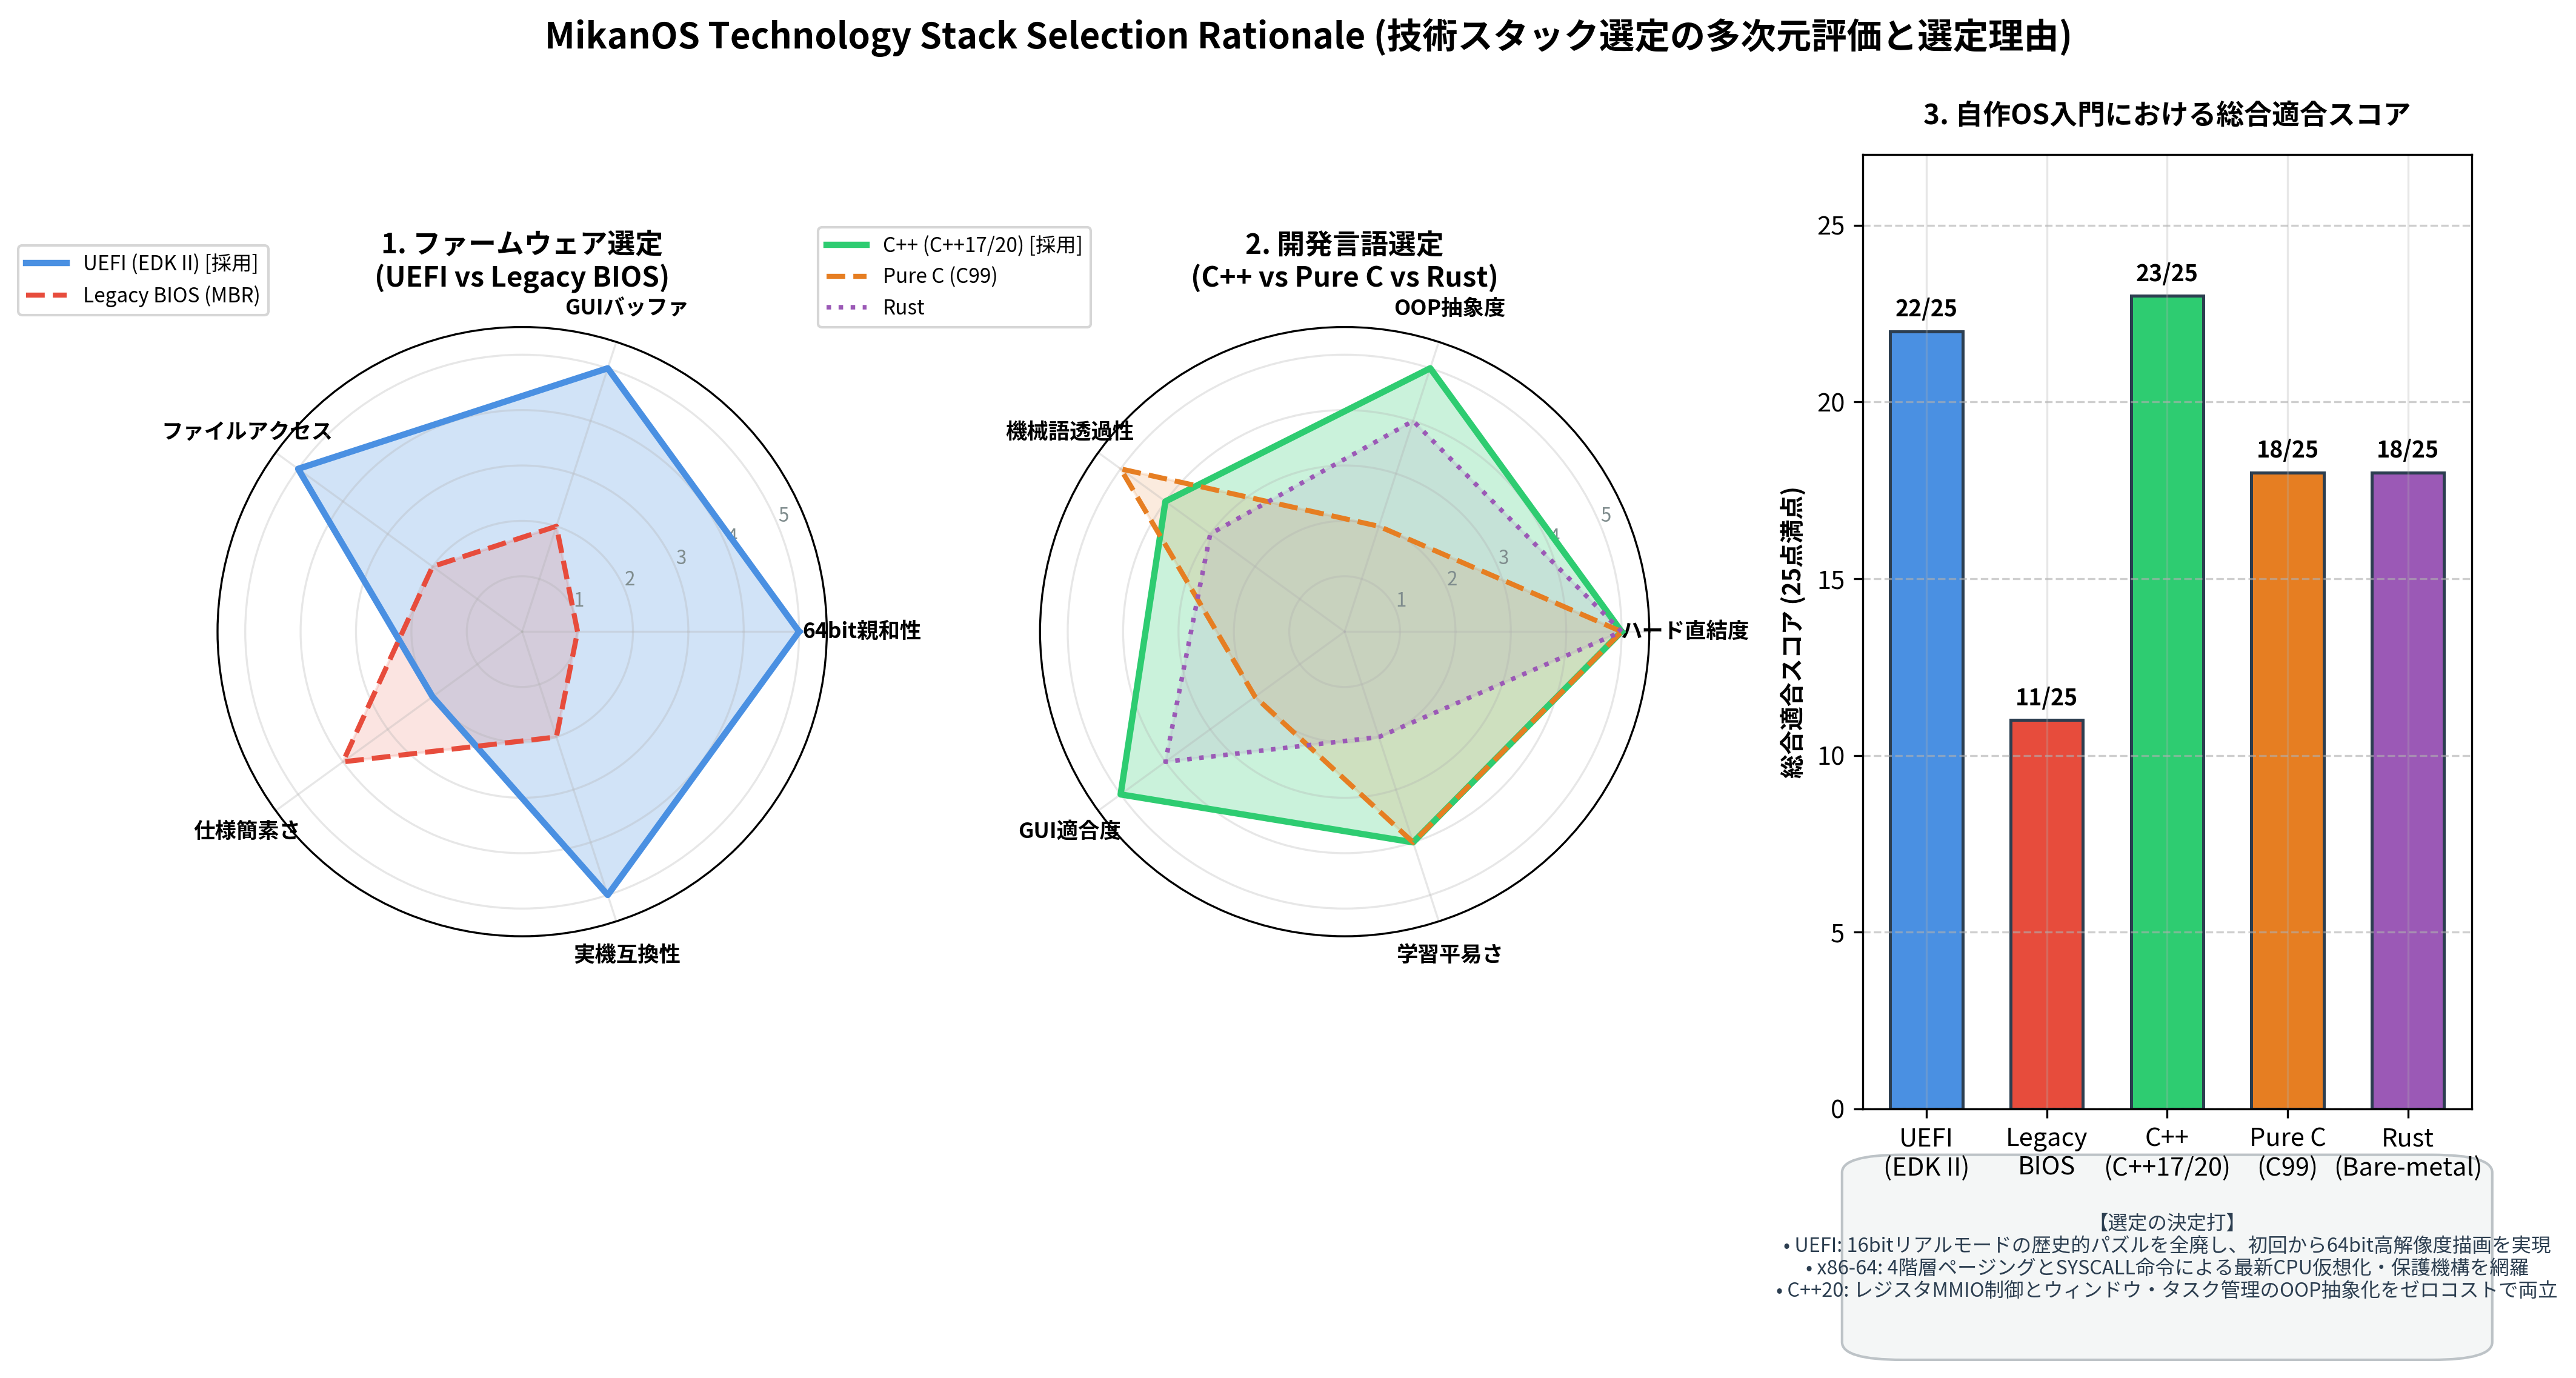

In [4]:
# 図版生成 2: 技術スタック選定の多次元評価レーダーチャート & 比較マトリクス
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style

setup_plot_style()
fig = plt.figure(figsize=(16, 7.5), dpi=300)
fig.suptitle("MikanOS Technology Stack Selection Rationale (技術スタック選定の多次元評価と選定理由)",
             fontsize=14, weight="bold", y=0.98)

radar_categories_fw = ["64bit親和性", "GUIバッファ", "ファイルアクセス", "仕様簡素さ", "実機互換性"]
radar_categories_lang = ["ハード直結度", "OOP抽象度", "機械語透過性", "GUI適合度", "学習平易さ"]

N = len(radar_categories_fw)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

# Subplot 1: Firmware Radar
ax_fw = fig.add_subplot(1, 3, 1, polar=True)
fw_uefi = [5, 5, 5, 2, 5]
fw_bios = [1, 2, 2, 4, 2]
fw_uefi += fw_uefi[:1]
fw_bios += fw_bios[:1]

ax_fw.plot(angles, fw_uefi, color="#4A90E2", linewidth=2.5, linestyle="solid", label="UEFI (EDK II) [採用]")
ax_fw.fill(angles, fw_uefi, color="#4A90E2", alpha=0.25)

ax_fw.plot(angles, fw_bios, color="#E74C3C", linewidth=2.0, linestyle="dashed", label="Legacy BIOS (MBR)")
ax_fw.fill(angles, fw_bios, color="#E74C3C", alpha=0.15)

ax_fw.set_xticks(angles[:-1])
ax_fw.set_xticklabels(radar_categories_fw, fontsize=8.5, weight="bold")
ax_fw.set_ylim(0, 5.5)
ax_fw.set_yticks([1, 2, 3, 4, 5])
ax_fw.set_yticklabels(["1", "2", "3", "4", "5"], fontsize=7.5, color="#7F8C8D")
ax_fw.set_title("1. ファームウェア選定\n(UEFI vs Legacy BIOS)", fontsize=11, weight="bold", pad=16)
ax_fw.legend(loc="upper right", bbox_to_anchor=(0.1, 1.15), fontsize=8.0)

# Subplot 2: Language Radar
ax_lang = fig.add_subplot(1, 3, 2, polar=True)
lang_cpp = [5, 5, 4, 5, 4]
lang_c = [5, 2, 5, 2, 4]
lang_rust = [5, 4, 3, 4, 2]
lang_cpp += lang_cpp[:1]
lang_c += lang_c[:1]
lang_rust += lang_rust[:1]

ax_lang.plot(angles, lang_cpp, color="#2ECC71", linewidth=2.5, linestyle="solid", label="C++ (C++17/20) [採用]")
ax_lang.fill(angles, lang_cpp, color="#2ECC71", alpha=0.25)

ax_lang.plot(angles, lang_c, color="#E67E22", linewidth=2.0, linestyle="dashed", label="Pure C (C99)")
ax_lang.fill(angles, lang_c, color="#E67E22", alpha=0.15)

ax_lang.plot(angles, lang_rust, color="#9B59B6", linewidth=1.8, linestyle="dotted", label="Rust")
ax_lang.fill(angles, lang_rust, color="#9B59B6", alpha=0.10)

ax_lang.set_xticks(angles[:-1])
ax_lang.set_xticklabels(radar_categories_lang, fontsize=8.5, weight="bold")
ax_lang.set_ylim(0, 5.5)
ax_lang.set_yticks([1, 2, 3, 4, 5])
ax_lang.set_yticklabels(["1", "2", "3", "4", "5"], fontsize=7.5, color="#7F8C8D")
ax_lang.set_title("2. 開発言語選定\n(C++ vs Pure C vs Rust)", fontsize=11, weight="bold", pad=16)
ax_lang.legend(loc="upper right", bbox_to_anchor=(0.1, 1.18), fontsize=8.0)

# Subplot 3: Bar Chart
ax_bar = fig.add_subplot(1, 3, 3)
technologies = ["UEFI\n(EDK II)", "Legacy\nBIOS", "C++\n(C++17/20)", "Pure C\n(C99)", "Rust\n(Bare-metal)"]
scores = [22, 11, 23, 18, 18]
colors = ["#4A90E2", "#E74C3C", "#2ECC71", "#E67E22", "#9B59B6"]

bars = ax_bar.bar(technologies, scores, color=colors, width=0.6, edgecolor="#2C3E50", linewidth=1.2)
ax_bar.set_ylim(0, 27)
ax_bar.set_ylabel("総合適合スコア (25点満点)", fontsize=9.5, weight="bold")
ax_bar.set_title("3. 自作OS入門における総合適合スコア", fontsize=11, weight="bold", pad=12)
ax_bar.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    height = bar.get_height()
    ax_bar.annotate(f"{height}/25",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9.0, weight="bold")

rationale_box = patches.FancyBboxPatch((-0.4, -6.8), 4.8, 5.2, boxstyle="round,pad=0.3,rounding_size=0.5",
                                       facecolor="#F4F6F6", edgecolor="#BDC3C7", linewidth=1.0, clip_on=False)
ax_bar.add_patch(rationale_box)
ax_bar.text(2.0, -4.2,
            "【選定の決定打】\n"
            "• UEFI: 16bitリアルモードの歴史的パズルを全廃し、初回から64bit高解像度描画を実現\n"
            "• x86-64: 4階層ページングとSYSCALL命令による最新CPU仮想化・保護機構を網羅\n"
            "• C++20: レジスタMMIO制御とウィンドウ・タスク管理のOOP抽象化をゼロコストで両立",
            fontsize=7.8, color="#2C3E50", ha="center", va="center", clip_on=False)

plt.subplots_adjust(top=0.88, bottom=0.18, wspace=0.35)
out_path_2 = result_dir / "fig0_10_tech_stack_selection_rationale.png"
fig.savefig(out_path_2, bbox_inches="tight", dpi=300)
plt.close(fig)
print(f"図版 2 を保存しました: {out_path_2.name} ({out_path_2.stat().st_size:,} bytes)")
display(Image(filename=str(out_path_2)))


## 6. Python によるアーキテクチャ分析・モジュール依存関係シミュレーション

`common.os_sim` に定義された `MikanOSArchitectureRoadmap` と `TechStackComparison` を用い、全モジュールの依存関係深さや各フェーズの統計メトリクスを対話的に分析します。

In [5]:
# Python によるアーキテクチャ分析・モジュール依存関係シミュレーション
from common import (
    MikanOSArchitectureRoadmap,
    TechStackComparison,
)

phases = MikanOSArchitectureRoadmap.get_phases()
print(f"=== MikanOS 7大フェーズ構成統計 (全 {len(phases)} フェーズ) ===")
for p in phases:
    ch_count = p.end_chapter - p.start_chapter + 1
    print(f"[Phase {p.phase_id}] {p.name:<24} | {p.chapter_range:<14} ({ch_count} 章分) | マイルストーン数: {len(p.key_milestones)}")

print("\n=== 主要カーネルモジュールと依存関係深さ ===")
modules = MikanOSArchitectureRoadmap.get_core_modules()
dep_map = MikanOSArchitectureRoadmap.calculate_module_dependencies()

def get_depth(name: str) -> int:
    deps = dep_map.get(name, [])
    if not deps:
        return 0
    return 1 + max(get_depth(d) for d in deps)

for m in modules:
    depth = get_depth(m.module_name)
    deps_str = ", ".join(m.dependencies) if m.dependencies else "(none)"
    print(f"{m.module_name:<20} (Ch.{m.chapter:2d}, Layer: {m.layer:<10}) | 依存深さ: {depth} | 依存先: {deps_str}")


=== MikanOS 7大フェーズ構成統計 (全 7 フェーズ) ===
[Phase 1] ブートとグラフィックス基盤            | 第1章 〜 第5章      (5 章分) | マイルストーン数: 5
[Phase 2] 入力デバイスと割り込み機構            | 第6章 〜 第7章      (2 章分) | マイルストーン数: 5
[Phase 3] メモリ管理とGUIレイヤ重ね合わせ        | 第8章 〜 第10章     (3 章分) | マイルストーン数: 5
[Phase 4] 時間計測・キーボードとマルチタスク        | 第11章 〜 第14章    (4 章分) | マイルストーン数: 5
[Phase 5] ターミナル・コマンドとファイルシステム      | 第15章 〜 第18章    (4 章分) | マイルストーン数: 5
[Phase 6] 4階層ページングとシステムコール保護       | 第19章 〜 第23章    (5 章分) | マイルストーン数: 6
[Phase 7] 実用OSへの洗練・IPCとアプリケーション    | 第24章 〜 第30章    (7 章分) | マイルストーン数: 6

=== 主要カーネルモジュールと依存関係深さ ===
PixelWriter          (Ch. 4, Layer: HAL       ) | 依存深さ: 0 | 依存先: (none)
Console              (Ch. 5, Layer: KernelCore) | 依存深さ: 1 | 依存先: PixelWriter
PCIManager           (Ch. 6, Layer: HAL       ) | 依存深さ: 0 | 依存先: (none)
xHCIDriver           (Ch. 6, Layer: HAL       ) | 依存深さ: 1 | 依存先: PCIManager
IDTManager           (Ch. 7, Layer: KernelCore) | 依存深さ: 0 | 依存先: (none)
ArrayQueue           (Ch. 7, Layer: KernelCore) | 依存深さ

## 7. まとめと第1章への突入準備

本節を通じて、MikanOS の全体アーキテクチャロードマップと、現代的技術スタック（UEFI / x86-64 / C++20）選定の必然性を完全に理解しました。

### 第0章全体の振り返り（OS自作の基礎理論完全制覇）
- **0.1 OSの作り方**: Linux・はりぼてOS・MikanOSの規模を比較し、段階的成長曲線を可視化
- **0.2 そもそもOSって何？**: ハードウェア抽象化・リソース管理・POSIX仕様とNewlibの役割
- **0.3 OS自作の手順**: コンパイル・リンク・ブートメディア作成とQEMUモニタデバッグ
- **0.4 OS自作の楽しみ方**: スモールステップ開発哲学と、printfのない世界の5大デバッグ思考法
- **0.5 OS自作の全体像**: 全30章・7大フェーズのロードマップと、UEFI・x86-64・C++20の技術的必然性

---

### 🚀 いよいよ第1章へ！
理論の準備はすべて整いました。次の **第1章「PCの仕組みとハローワールド」** では、いよいよエディタを開き、バイナリを手打ちして最小の UEFI アプリケーション（`BOOTX64.EFI`）をビルドし、画面に文字を表示させる最初の感動の瞬間を迎えます！